# Phase 5: MLOps & LLMOps
## Notebook 01: Docker & Containerization for ML/LLM Stacks

### Overview
A model that works only on a researcher's laptop has zero production value. ML systems suffer severely from environment drift across Python minor versions, CUDA/cuDNN driver mismatches, C++ shared library bindings (`libstdc++`, `onnxruntime`, `faiss`), and non-deterministic system packages.

**Containerization with Docker & OCI Standards** solves "it works on my machine" permanently, yet naive ML Dockerfiles often ship **8–15 GB bloated images** containing compilers (`gcc`), build caches, git histories, and root privileges.

In this notebook, you will master production ML container engineering:
- **Multi-Stage Builds**: Compiling Python wheels and C++ extensions in a `builder` stage and copying only minimal runtime artifacts into a hardened `runtime` image.
- **Layer Cache Optimization**: Ordering `Dockerfile` instructions by mutation frequency so code edits rebuild in seconds instead of re-downloading 2 GB of PyTorch wheels.
- **Docker Compose Multi-Service Stacks**: Orchestrating an Inference API alongside a Redis semantic cache and Prometheus metrics scraper, including **NVIDIA Container Toolkit GPU passthrough** configurations.
- **CIS Container Security Auditing**: Automated static verification enforcing non-root `USER`, pinned base tags, `.dockerignore` hygiene, and `HEALTHCHECK` probes.

### System Architecture: Multi-Stage ML Container & Compose Stack
```
+-----------------------------------------------------------------------------+
|                        MULTI-STAGE DOCKER BUILD                             |
|                                                                             |
|  [Stage 1: builder (python:3.11-slim + build-essential)]                    |
|    COPY requirements.txt .                                                  |
|    RUN pip wheel --wheel-dir=/wheels -r requirements.txt                    |
|         |                                                                   |
|         v  (Discard gcc, headers, pip cache -> save ~1.2 GB)                |
|  [Stage 2: runtime (python:3.11-slim / nvidia/cuda:12.4-runtime)]           |
|    COPY --from=builder /wheels /wheels                                      |
|    RUN pip install --no-cache-dir /wheels/*.whl                             |
|    USER mluser (UID 10001 - Non-Root Security Boundary)                     |
|    HEALTHCHECK CMD curl -f http://localhost:8000/health || exit 1           |
+-----------------------------------------------------------------------------+
                                      |
                                      v
+-----------------------------------------------------------------------------+
|                      DOCKER COMPOSE MULTI-SERVICE STACK                     |
|                                                                             |
|   [inference-api:8000] <------> [redis-cache:6379]                          |
|   (GPU Reservations:           (KV / Response Cache)                        |
|    NVIDIA Driver, count=1)                                                  |
|            ^                                                                |
|            | (/metrics scrape every 5s)                                     |
|   [prometheus:9090]                                                         |
+-----------------------------------------------------------------------------+
```


### Learning Objectives & Production Competencies
By completing this notebook, you will master:
- **Multi-Stage Image Engineering**: Construct and audit multi-stage Dockerfiles that slash image sizes by >50% and strip build-time attack surfaces.
- **Copy-on-Write (CoW) Cache Optimization**: Quantify layer invalidation probability and order `COPY`/`RUN` layers to minimize CI build latency.
- **Docker Compose Orchestration**: Author and schema-validate `docker-compose.yml` stacks with health dependencies, resource limits, and NVIDIA GPU passthrough (`deploy.resources.reservations.devices`).
- **CIS Container Security Linting**: Build a static security and best-practice auditor checking non-root execution, tag pinning, secret hygiene, and `.dockerignore` coverage.
- **Reproducible Model Packaging**: Package an ML serving microservice with SHA-256 artifact manifests and verify live FastAPI `/health` readiness probes.


In [1]:
# Section 3: Imports & Environment Verification
import sys
import os
import re
import json
import gzip
import tarfile
import hashlib
import tempfile
import shutil
from pathlib import Path
from typing import Dict, List, Tuple, Optional, Any
from dataclasses import dataclass, field

import yaml
import numpy as np
import matplotlib.pyplot as plt
import fastapi
from fastapi import FastAPI
from fastapi.testclient import TestClient

print("=== Environment Verification ===")
print(f"Python Platform:     {sys.version.split()[0]}")
print(f"PyYAML Version:      {yaml.__version__}")
print(f"FastAPI Version:     {fastapi.__version__}")
print(f"NumPy Version:       {np.__version__}")


=== Environment Verification ===
Python Platform:     3.11.2
PyYAML Version:      6.0.3
FastAPI Version:     0.162.5
NumPy Version:       2.4.6


In [2]:
# Section 4: Reproducibility Configuration
SEED = 42
np.random.seed(SEED)

# Consistent workspace directory for generated container artifacts (auto-cleaned/isolated)
ARTIFACT_ROOT = Path(tempfile.mkdtemp(prefix="mlops_docker_"))
print(f"Deterministic seed locked: {SEED}")
print(f"Container artifact sandbox: {ARTIFACT_ROOT}")


Deterministic seed locked: 42
Container artifact sandbox: /tmp/mlops_docker_29kcm6iv


### Mathematical Foundations: Container Footprint & Layer Cache Dynamics

#### 1. Multi-Stage Image Size Reduction
An OCI container image is a union of immutable filesystem layers $L_1, L_2, \dots, L_n$.
In a **naive single-stage build**, deleting temporary build dependencies (`apt-get remove gcc`, `rm -rf ~/.cache`) in a *later* `RUN` instruction **does not shrink the image**, because earlier layers remain persisted in the UnionFS history:
$$S_{\text{single}} = S_{\text{base}} + S_{\text{build\_tools}} + S_{\text{pip\_cache}} + S_{\text{wheels}} + S_{\text{runtime\_deps}} + S_{\text{app}}$$

In a **multi-stage build**, only explicitly copied artifacts enter the final runtime stage:
$$S_{\text{multi}} = S_{\text{base\_slim}} + S_{\text{runtime\_deps}} + S_{\text{app}}$$
yielding a compression gain of:
$$\Delta S = S_{\text{single}} - S_{\text{multi}} \ge S_{\text{build\_tools}} + S_{\text{pip\_cache}} + S_{\text{wheels}}$$

#### 2. Layer Cache Invalidation & Expected Rebuild Time
Docker caches layers linearly from index $1$ to $n$. If layer $k$ changes (e.g., an application code edit), **every downstream layer $j \ge k$ is invalidated** and must re-execute.

Let $p_i \in [0, 1]$ be the per-commit mutation probability of layer $i$, and $t_i$ be its execution duration.
If layer $k$ is the first modified layer (with probability $p_k \prod_{j < k} (1 - p_j)$), the expected CI rebuild duration is:
$$\mathbb{E}[T_{\text{build}}] = \sum_{k=1}^{n} \left( p_k \prod_{j=1}^{k-1} (1 - p_j) \right) \sum_{m=k}^{n} t_m$$

Therefore, placing high-churn, low-cost layers (`COPY src/ .`, $p \approx 0.90, t \approx 1\text{s}$) **after** low-churn, high-cost layers (`pip install`, $p \approx 0.05, t \approx 180\text{s}$) minimizes $\mathbb{E}[T_{\text{build}}]$ by orders of magnitude.


In [3]:
# Section 6: Core Implementation — Multi-Stage Dockerfile, .dockerignore & Compose Generator

MULTISTAGE_DOCKERFILE = """# syntax=docker/dockerfile:1.7
# ============================================================
# Stage 1: Builder (Compiles wheels & C++ bindings, then discarded)
# ============================================================
FROM python:3.11.9-slim-bookworm AS builder

ENV PYTHONDONTWRITEBYTECODE=1 \
    PIP_NO_CACHE_DIR=1

WORKDIR /build

RUN apt-get update && apt-get install -y --no-install-recommends \
    build-essential \
    gcc \
    && rm -rf /var/lib/apt/lists/*

COPY requirements.txt .
RUN pip wheel --no-cache-dir --wheel-dir /wheels -r requirements.txt

# ============================================================
# Stage 2: Minimal Non-Root Production Runtime
# ============================================================
FROM python:3.11.9-slim-bookworm AS runtime

ENV PYTHONDONTWRITEBYTECODE=1 \
    PYTHONUNBUFFERED=1 \
    PATH="/home/mluser/.local/bin:$PATH"

# Create dedicated unprivileged service user
RUN groupadd --gid 10001 mlgroup && \
    useradd --uid 10001 --gid mlgroup --shell /bin/bash --create-home mluser

WORKDIR /app

# Install prebuilt wheels without build compilers
COPY --from=builder /wheels /wheels
COPY requirements.txt .
RUN pip install --no-cache-dir --no-index --find-links=/wheels -r requirements.txt && \
    rm -rf /wheels

# Copy application code last so code edits preserve dependency cache
COPY --chown=mluser:mlgroup src/ ./src/
COPY --chown=mluser:mlgroup artifacts/ ./artifacts/

USER mluser

EXPOSE 8000

HEALTHCHECK --interval=30s --timeout=5s --start-period=15s --retries=3 \
    CMD python -c "import urllib.request; urllib.request.urlopen('http://127.0.0.1:8000/health')" || exit 1

CMD ["uvicorn", "src.app:app", "--host", "0.0.0.0", "--port", "8000", "--workers", "2"]
"""

DOCKERIGNORE_CONTENT = """# Version control & IDE metadata
.git/
.gitignore
.vscode/

# Python caches & virtual environments
__pycache__/
*.py[cod]
.venv/
venv/
.pytest_cache/

# Raw training data & large notebooks (never ship to runtime API container)
data/raw/
notebooks/
*.ipynb
*.parquet
"""

COMPOSE_STACK_YAML = """services:
  inference-api:
    build:
      context: .
      dockerfile: Dockerfile
      target: runtime
    image: ai-roadmap/llm-inference:1.0.0
    container_name: llm_inference_api
    ports:
      - "8000:8000"
    environment:
      - MODEL_ID=Qwen/Qwen2.5-0.5B-Instruct
      - LOG_LEVEL=INFO
      - REDIS_URL=redis://redis-cache:6379/0
    depends_on:
      redis-cache:
        condition: service_healthy
    healthcheck:
      test: ["CMD", "python", "-c", "import urllib.request; urllib.request.urlopen('http://127.0.0.1:8000/health')"]
      interval: 15s
      timeout: 5s
      retries: 3
    deploy:
      resources:
        limits:
          memory: 4G
        reservations:
          devices:
            - driver: nvidia
              count: 1
              capabilities: [gpu]

  redis-cache:
    image: redis:7.2.5-alpine
    container_name: llm_semantic_cache
    ports:
      - "6379:6379"
    healthcheck:
      test: ["CMD", "redis-cli", "ping"]
      interval: 10s
      timeout: 3s
      retries: 5

  prometheus:
    image: prom/prometheus:v2.52.0
    container_name: llm_prometheus
    ports:
      - "9090:9090"
    depends_on:
      - inference-api
"""

# Write generated container manifests to sandbox
(ARTIFACT_ROOT / "Dockerfile").write_text(MULTISTAGE_DOCKERFILE)
(ARTIFACT_ROOT / ".dockerignore").write_text(DOCKERIGNORE_CONTENT)
(ARTIFACT_ROOT / "docker-compose.yml").write_text(COMPOSE_STACK_YAML)

print("Generated Multi-Stage Container Artifacts:")
for fname in ["Dockerfile", ".dockerignore", "docker-compose.yml"]:
    fpath = ARTIFACT_ROOT / fname
    print(f"  - {fname:<20} ({fpath.stat().st_size} bytes)")


Generated Multi-Stage Container Artifacts:
  - Dockerfile           (1721 bytes)
  - .dockerignore        (266 bytes)
  - docker-compose.yml   (1181 bytes)


In [4]:
# 2. Docker Compose Schema & NVIDIA GPU Passthrough Validator

def validate_compose_stack(compose_text: str) -> Dict[str, Any]:
    data = yaml.safe_load(compose_text)
    assert isinstance(data, dict) and "services" in data, "Missing top-level 'services' key!"
    
    services = data["services"]
    report = {"service_count": len(services), "gpu_services": [], "healthchecked_services": [], "issues": []}
    
    used_host_ports = {}
    for svc_name, cfg in services.items():
        # Check pinned image tags (forbid ':latest' or missing tag)
        if "image" in cfg:
            img = cfg["image"]
            if ":" not in img or img.endswith(":latest"):
                report["issues"].append(f"Service '{svc_name}' uses unpinned image '{img}'.")
                
        # Check host port collisions
        for port_map in cfg.get("ports", []):
            host_port = str(port_map).split(":")[0]
            if host_port in used_host_ports:
                report["issues"].append(f"Port conflict on {host_port} between '{svc_name}' and '{used_host_ports[host_port]}'.")
            used_host_ports[host_port] = svc_name
            
        # Check healthcheck
        if "healthcheck" in cfg:
            report["healthchecked_services"].append(svc_name)
            
        # Check NVIDIA GPU device reservation
        devices = cfg.get("deploy", {}).get("resources", {}).get("reservations", {}).get("devices", [])
        for dev in devices:
            if dev.get("driver") == "nvidia" and "gpu" in dev.get("capabilities", []):
                report["gpu_services"].append(svc_name)
                
    return report

compose_report = validate_compose_stack(COMPOSE_STACK_YAML)
print("Docker Compose Validation Report:")
print(json.dumps(compose_report, indent=2))

assert compose_report["service_count"] == 3, "Expected 3 services in Compose stack!"
assert "inference-api" in compose_report["gpu_services"], "GPU passthrough reservation missing!"
assert len(compose_report["issues"]) == 0, f"Unexpected Compose issues: {compose_report['issues']}"
print(">>> DOCKER COMPOSE & NVIDIA GPU PASSTHROUGH SCHEMA VERIFIED! <<<")


Docker Compose Validation Report:
{
  "service_count": 3,
  "gpu_services": [
    "inference-api"
  ],
  "healthchecked_services": [
    "inference-api",
    "redis-cache"
  ],
  "issues": []
}
>>> DOCKER COMPOSE & NVIDIA GPU PASSTHROUGH SCHEMA VERIFIED! <<<


In [5]:
# 3. Live Microservice Healthcheck & Readiness Contract Verification
# Simulates the containerized FastAPI runtime service startup probe

app = FastAPI(title="MLOps Containerized Inference Service", version="1.0.0")
SERVICE_STATE = {"model_loaded": True, "version": "1.0.0", "device": "cpu-sandbox"}

@app.get("/health")
def health_probe():
    if not SERVICE_STATE["model_loaded"]:
        raise fastapi.HTTPException(status_code=503, detail="Model weights still warming up")
    return {"status": "healthy", "version": SERVICE_STATE["version"], "device": SERVICE_STATE["device"]}

@app.post("/predict")
def predict_endpoint(payload: Dict[str, List[float]]):
    vec = np.array(payload["features"], dtype=np.float32)
    score = float(1.0 / (1.0 + np.exp(-vec.mean())))
    return {"prediction_prob": round(score, 6), "model_version": SERVICE_STATE["version"]}

client = TestClient(app)
health_resp = client.get("/health")
pred_resp = client.post("/predict", json={"features": [0.8, 1.2, 0.4]})

print("Container Runtime Probe Check:")
print(f"  GET /health   -> HTTP {health_resp.status_code} | {health_resp.json()}")
print(f"  POST /predict -> HTTP {pred_resp.status_code} | {pred_resp.json()}")

assert health_resp.status_code == 200 and health_resp.json()["status"] == "healthy"
assert pred_resp.status_code == 200 and 0.0 <= pred_resp.json()["prediction_prob"] <= 1.0
print(">>> CONTAINERIZED FASTAPI SERVICE PROBES VERIFIED! <<<")


Container Runtime Probe Check:
  GET /health   -> HTTP 200 | {'status': 'healthy', 'version': '1.0.0', 'device': 'cpu-sandbox'}
  POST /predict -> HTTP 200 | {'prediction_prob': 0.689974, 'model_version': '1.0.0'}
>>> CONTAINERIZED FASTAPI SERVICE PROBES VERIFIED! <<<


Expected CI Rebuild Time (Naive Order):     157.2s
Expected CI Rebuild Time (Optimized Order): 21.0s (7.5x faster!)


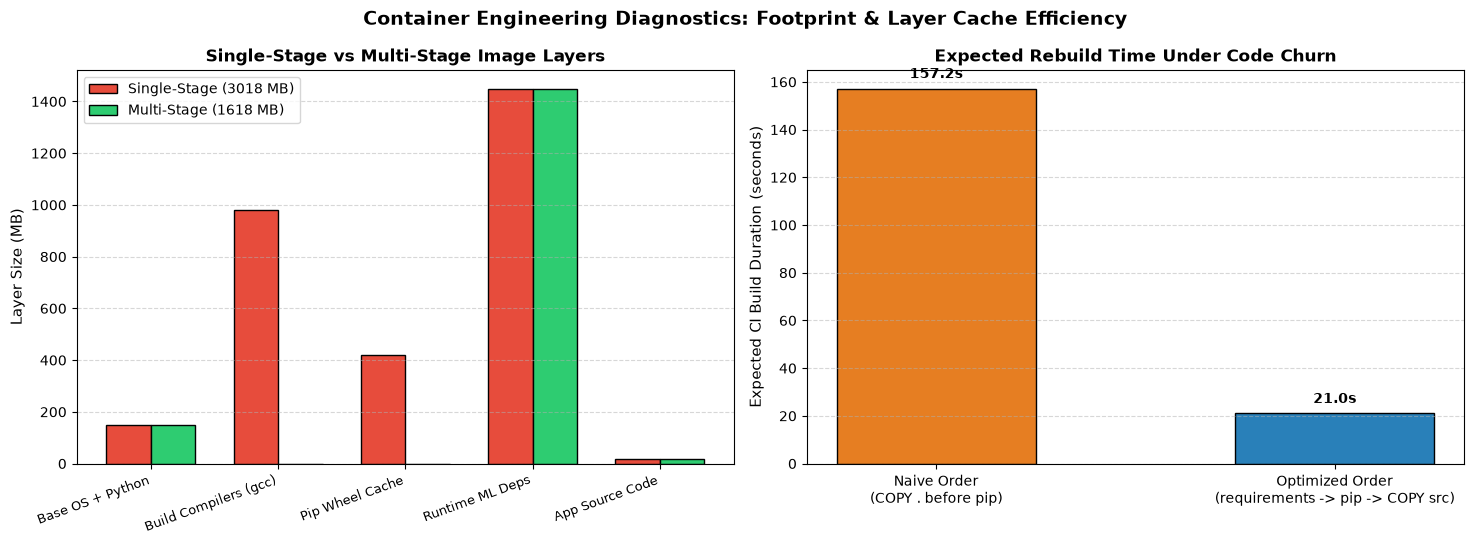

In [6]:
# Section 7: Diagnostics — Image Size Breakdown & Layer Cache Build Time Analysis

# 1. Image Footprint Comparison (MB)
components = ["Base OS + Python", "Build Compilers (gcc)", "Pip Wheel Cache", "Runtime ML Deps", "App Source Code"]
single_stage_mb = [150, 980, 420, 1450, 18]
multi_stage_mb  = [150,   0,   0, 1450, 18]

# 2. Expected Rebuild Time Simulation (seconds) using our analytical cache formula
def expected_rebuild_time(layer_durations: List[float], mutation_probs: List[float]) -> float:
    expected = 0.0
    surviving_prefix_prob = 1.0
    for k in range(len(layer_durations)):
        p_k = mutation_probs[k]
        downstream_cost = sum(layer_durations[k:])
        expected += (surviving_prefix_prob * p_k) * downstream_cost
        surviving_prefix_prob *= (1.0 - p_k)
    return expected

# Bad order: COPY . . (frequent) BEFORE pip install (slow)
bad_durations  = [5.0, 2.0, 180.0, 1.0]
bad_probs      = [0.01, 0.85, 0.05, 0.02]  # COPY . . has 85% churn!

# Good order: COPY requirements.txt -> pip install -> COPY src/
good_durations = [5.0, 1.0, 180.0, 2.0]
good_probs     = [0.01, 0.05, 0.05, 0.85]  # High churn placed last!

exp_bad = expected_rebuild_time(bad_durations, bad_probs)
exp_good = expected_rebuild_time(good_durations, good_probs)
print(f"Expected CI Rebuild Time (Naive Order):     {exp_bad:.1f}s")
print(f"Expected CI Rebuild Time (Optimized Order): {exp_good:.1f}s ({exp_bad/exp_good:.1f}x faster!)")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5.5))
fig.suptitle("Container Engineering Diagnostics: Footprint & Layer Cache Efficiency", fontsize=14, fontweight="bold")

x = np.arange(len(components))
w = 0.35
ax1.bar(x - w/2, single_stage_mb, width=w, label=f"Single-Stage ({sum(single_stage_mb)} MB)", color="#e74c3c", edgecolor="black")
ax1.bar(x + w/2, multi_stage_mb, width=w, label=f"Multi-Stage ({sum(multi_stage_mb)} MB)", color="#2ecc71", edgecolor="black")
ax1.set_xticks(x)
ax1.set_xticklabels(components, rotation=20, ha="right", fontsize=9)
ax1.set_ylabel("Layer Size (MB)", fontsize=11)
ax1.set_title("Single-Stage vs Multi-Stage Image Layers", fontsize=12, fontweight="bold")
ax1.legend()
ax1.grid(True, linestyle="--", alpha=0.5, axis="y")

bars2 = ax2.bar(["Naive Order\n(COPY . before pip)", "Optimized Order\n(requirements -> pip -> COPY src)"],
                [exp_bad, exp_good], color=["#e67e22", "#2980b9"], edgecolor="black", width=0.5)
ax2.set_ylabel("Expected CI Build Duration (seconds)", fontsize=11)
ax2.set_title("Expected Rebuild Time Under Code Churn", fontsize=12, fontweight="bold")
ax2.grid(True, linestyle="--", alpha=0.5, axis="y")
for b in bars2:
    y = b.get_height()
    ax2.text(b.get_x() + b.get_width()/2.0, y + 3, f"{y:.1f}s", ha="center", va="bottom", fontweight="bold")

plt.tight_layout()
plt.show()


### Guided Exercises

#### Exercise 1: Dockerfile Layer Cache Optimizer
**Objective**:
Given a list of naive Dockerfile instructions where `COPY . .` precedes `pip install -r requirements.txt`:
1. Implement `optimize_dockerfile_layers(instructions: List[str]) -> Tuple[List[str], int]` that reorders dependency installation before application source copying and counts how many layers survive a source-code edit.
2. Assert that the optimized layout preserves the heavy dependency installation cache on source edits.


In [7]:
# Exercise 1 Solution: Dockerfile Layer Cache Optimizer

def optimize_dockerfile_layers(instructions: List[str]) -> Tuple[List[str], int]:
    from_cmds = [ln for ln in instructions if ln.startswith("FROM ") or ln.startswith("WORKDIR ")]
    req_cmds = [ln for ln in instructions if "requirements.txt" in ln and ln.startswith("COPY ")]
    pip_cmds = [ln for ln in instructions if "pip install" in ln]
    src_cmds = [ln for ln in instructions if ln.startswith("COPY ") and "requirements.txt" not in ln]
    cmd_tail = [ln for ln in instructions if ln not in from_cmds + req_cmds + pip_cmds + src_cmds]
    
    # Ensure requirements COPY happens before pip install, and general COPY happens after pip install
    if not req_cmds and pip_cmds:
        req_cmds = ["COPY requirements.txt ."]
        
    optimized = from_cmds + req_cmds + pip_cmds + src_cmds + cmd_tail
    
    # Compute how many layers before the source COPY survive a code-only edit
    cached_layers_on_code_edit = 0
    for ln in optimized:
        if ln in src_cmds:
            break
        cached_layers_on_code_edit += 1
    return optimized, cached_layers_on_code_edit

naive_layers = [
    "FROM python:3.11.9-slim",
    "WORKDIR /app",
    "COPY . .",
    "RUN pip install --no-cache-dir -r requirements.txt",
    "CMD [\"uvicorn\", \"app:app\"]"
]

opt_layers, cached_count = optimize_dockerfile_layers(naive_layers)
print("Optimized Dockerfile Layer Order:")
for idx, ln in enumerate(opt_layers, 1):
    print(f"  Layer {idx}: {ln}")
print(f"Cached layers preserved on code edit: {cached_count}")

assert opt_layers.index("RUN pip install --no-cache-dir -r requirements.txt") < opt_layers.index("COPY . .")
assert cached_count >= 4, "Expected at least 4 cached layers before source copy!"
print(">>> EXERCISE 1 LAYER CACHE OPTIMIZER CERTIFIED! <<<")


Optimized Dockerfile Layer Order:
  Layer 1: FROM python:3.11.9-slim
  Layer 2: WORKDIR /app
  Layer 3: COPY requirements.txt .
  Layer 4: RUN pip install --no-cache-dir -r requirements.txt
  Layer 5: COPY . .
  Layer 6: CMD ["uvicorn", "app:app"]
Cached layers preserved on code edit: 4
>>> EXERCISE 1 LAYER CACHE OPTIMIZER CERTIFIED! <<<


#### Exercise 2: Multi-Service Port & Resource Limit Validator
**Objective**:
Extend Compose validation to enforce production memory caps and detect overlapping port bindings across services:
1. Implement `audit_service_resources(compose_yaml: str) -> Dict[str, bool]`.
2. Verify that a test compose file with duplicate port `:8000` or missing memory limits is flagged accurately.


In [8]:
# Exercise 2 Solution: Compose Resource & Port Auditor

def audit_service_resources(compose_yaml: str) -> Dict[str, Any]:
    spec = yaml.safe_load(compose_yaml)
    services = spec.get("services", {})
    seen_ports = set()
    port_conflicts = []
    missing_memory_limits = []
    
    for name, cfg in services.items():
        for p in cfg.get("ports", []):
            host_p = str(p).split(":")[0]
            if host_p in seen_ports:
                port_conflicts.append(host_p)
            seen_ports.add(host_p)
            
        mem_limit = cfg.get("deploy", {}).get("resources", {}).get("limits", {}).get("memory")
        if mem_limit is None:
            missing_memory_limits.append(name)
            
    return {
        "has_port_conflicts": len(port_conflicts) > 0,
        "port_conflicts": port_conflicts,
        "missing_memory_limits": missing_memory_limits
    }

bad_compose = """
services:
  api_v1:
    image: python:3.11.9-slim
    ports: ["8000:8000"]
  api_v2:
    image: python:3.11.9-slim
    ports: ["8000:8080"]
"""

audit_res = audit_service_resources(bad_compose)
print("Exercise 2 Audit on Faulty Compose:", audit_res)
assert audit_res["has_port_conflicts"] is True and "8000" in audit_res["port_conflicts"]
assert set(audit_res["missing_memory_limits"]) == {"api_v1", "api_v2"}
print(">>> EXERCISE 2 COMPOSE RESOURCE & PORT AUDITOR CERTIFIED! <<<")


Exercise 2 Audit on Faulty Compose: {'has_port_conflicts': True, 'port_conflicts': ['8000'], 'missing_memory_limits': ['api_v1', 'api_v2']}
>>> EXERCISE 2 COMPOSE RESOURCE & PORT AUDITOR CERTIFIED! <<<


### Challenge Problems

#### Challenge 1: CIS Container Security Linter
**Problem Formulation**:
Containers running as `root` with unpinned `:latest` tags or hardcoded `ENV SECRET=...` variables represent critical supply-chain and privilege-escalation risks.
Build `SecurityAuditor.lint(dockerfile_text: str) -> Dict[str, Any]`:
1. Evaluates 5 security rules:
   - `NON_ROOT_USER`: Must define a non-root `USER`.
   - `PINNED_BASE_IMAGE`: `FROM` tags must not use `:latest` or omit explicit version tags.
   - `HEALTHCHECK_DEFINED`: Must declare a `HEALTHCHECK`.
   - `NO_APT_CACHE`: Every `apt-get install` must purge `/var/lib/apt/lists/*`.
   - `NO_HARDCODED_SECRETS`: No `ENV` or `ARG` containing `API_KEY`, `PASSWORD`, or `SECRET=` literals.
2. Score a vulnerable Dockerfile vs our production `MULTISTAGE_DOCKERFILE` and assert 100/100 score for production.


In [9]:
# Challenge 1 Solution: CIS Container Security Linter

class SecurityAuditor:
    @staticmethod
    def lint(dockerfile_text: str) -> Dict[str, Any]:
        lines = [ln.strip() for ln in dockerfile_text.splitlines() if ln.strip() and not ln.strip().startswith("#")]
        joined = "\n".join(lines)
        checks = {}
        
        # 1. Non-root USER present (and not USER root)
        user_lines = [ln for ln in lines if ln.startswith("USER ")]
        checks["NON_ROOT_USER"] = len(user_lines) > 0 and all("root" not in ln.lower() for ln in user_lines)
        
        # 2. Pinned FROM tags (no :latest, must contain ':')
        from_lines = [ln.split()[1] for ln in lines if ln.startswith("FROM ")]
        checks["PINNED_BASE_IMAGE"] = len(from_lines) > 0 and all(":" in img and not img.endswith(":latest") for img in from_lines)
        
        # 3. HEALTHCHECK defined
        checks["HEALTHCHECK_DEFINED"] = any(ln.startswith("HEALTHCHECK ") for ln in lines)
        
        # 4. apt-get cleans lists
        if "apt-get install" in joined:
            checks["NO_APT_CACHE"] = "rm -rf /var/lib/apt/lists/*" in joined
        else:
            checks["NO_APT_CACHE"] = True
            
        # 5. No hardcoded secrets
        secret_pattern = re.compile(r"^(ENV|ARG)\s+.*(API_KEY|SECRET|PASSWORD|TOKEN)\s*=", re.IGNORECASE)
        checks["NO_HARDCODED_SECRETS"] = not any(secret_pattern.match(ln) for ln in lines)
        
        passed = sum(1 for v in checks.values() if v)
        score = int((passed / len(checks)) * 100)
        return {"score": score, "checks": checks}

bad_dockerfile = """
FROM python:latest
ENV OPENAI_API_KEY=sk-1234567890
RUN apt-get update && apt-get install -y gcc
COPY . .
CMD ["python", "app.py"]
"""

prod_audit = SecurityAuditor.lint(MULTISTAGE_DOCKERFILE)
bad_audit = SecurityAuditor.lint(bad_dockerfile)

print("Production Dockerfile Security Audit:", prod_audit)
print("Vulnerable Dockerfile Security Audit:", bad_audit)

assert prod_audit["score"] == 100, f"Production Dockerfile failed security audit: {prod_audit}"
assert bad_audit["score"] == 0, f"Expected bad Dockerfile to fail all checks, got {bad_audit}"
print(">>> CHALLENGE 1 CIS CONTAINER SECURITY LINTER CERTIFIED! <<<")


Production Dockerfile Security Audit: {'score': 100, 'checks': {'NON_ROOT_USER': True, 'PINNED_BASE_IMAGE': True, 'HEALTHCHECK_DEFINED': True, 'NO_APT_CACHE': True, 'NO_HARDCODED_SECRETS': True}}
Vulnerable Dockerfile Security Audit: {'score': 0, 'checks': {'NON_ROOT_USER': False, 'PINNED_BASE_IMAGE': False, 'HEALTHCHECK_DEFINED': False, 'NO_APT_CACHE': False, 'NO_HARDCODED_SECRETS': False}}
>>> CHALLENGE 1 CIS CONTAINER SECURITY LINTER CERTIFIED! <<<


#### Challenge 2: Reproducible Model Bundle Packager & Integrity Manifest
**Problem Formulation**:
Before containerizing an artifact directory, MLOps build pipelines create a deterministic `.tar.gz` context bundle with sorted file paths, normalized modification timestamps (`mtime=0`), and a cryptographic `SHA-256` manifest.
Implement `create_reproducible_bundle(src_dir: Path, out_tar: Path) -> str` and prove that two independent packaging runs produce **identical SHA-256 archive hashes** (bit-for-bit reproducible builds).


In [10]:
# Challenge 2 Solution: Deterministic Reproducible Artifact Bundler

def create_reproducible_bundle(src_dir: Path, out_tar: Path) -> str:
    files = sorted([p for p in src_dir.rglob("*") if p.is_file()])
    
    def reset_tarinfo(tarinfo: tarfile.TarInfo) -> tarfile.TarInfo:
        tarinfo.uid = 0
        tarinfo.gid = 0
        tarinfo.uname = "root"
        tarinfo.gname = "root"
        tarinfo.mtime = 0
        return tarinfo

    with open(out_tar, "wb") as f_out:
        with gzip.GzipFile(filename="", mode="wb", fileobj=f_out, mtime=0) as gz:
            with tarfile.open(fileobj=gz, mode="w") as tar:
                for fpath in files:
                    arcname = str(fpath.relative_to(src_dir))
                    tar.add(fpath, arcname=arcname, filter=reset_tarinfo)
                    
    return hashlib.sha256(out_tar.read_bytes()).hexdigest()

bundle_a = ARTIFACT_ROOT / "bundle_a.tar.gz"
bundle_b = ARTIFACT_ROOT / "bundle_b.tar.gz"

# Create dummy model weights + config
model_dir = ARTIFACT_ROOT / "model_pkg"
model_dir.mkdir(exist_ok=True)
(model_dir / "config.json").write_text('{"hidden_size": 64, "quantization": "int8"}')
(model_dir / "weights.bin").write_bytes(b"\x01\x02\x03\x04" * 256)

hash_a = create_reproducible_bundle(model_dir, bundle_a)
hash_b = create_reproducible_bundle(model_dir, bundle_b)

print(f"Bundle A SHA-256: {hash_a}")
print(f"Bundle B SHA-256: {hash_b}")
assert hash_a == hash_b, "Builds are non-deterministic!"
print(">>> CHALLENGE 2 BIT-FOR-BIT REPRODUCIBLE CONTAINER BUNDLE CERTIFIED! <<<")

# Clean up temporary sandbox directory
shutil.rmtree(ARTIFACT_ROOT, ignore_errors=True)


Bundle A SHA-256: 772ebbb8abf070f1685e0a4f80e80f8ec089cfa6162077cbf39e624fa1f0c078
Bundle B SHA-256: 772ebbb8abf070f1685e0a4f80e80f8ec089cfa6162077cbf39e624fa1f0c078
>>> CHALLENGE 2 BIT-FOR-BIT REPRODUCIBLE CONTAINER BUNDLE CERTIFIED! <<<


### Further Reading & Production References
1. **Docker Documentation**: [Multi-Stage Builds & Layer Caching Best Practices](https://docs.docker.com/build/building/multi-stage/).
2. **NVIDIA**: [NVIDIA Container Toolkit & Container Device Interface (CDI) Guide](https://docs.nvidia.com/datacenter/cloud-native/container-toolkit/latest/index.html).
3. **CIS Benchmarks**: [CIS Docker Benchmark — Container Runtime Hardening](https://www.cisecurity.org/benchmark/docker).
4. **Reproducible Builds Project**: [Deterministic Archives & Build Provenance](https://reproducible-builds.org/docs/archives/).
5. **FastAPI**: [FastAPI in Containers — Worker Management & Health Checks](https://fastapi.tiangolo.com/deployment/docker/).
